<a href="https://colab.research.google.com/github/zzprogram/DSC1105/blob/main/SA1_CURIMATMAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

'data.frame':	3000 obs. of  10 variables:
 $ Customer_ID       : int  1 2 3 4 5 6 7 8 9 10 ...
 $ Gender            : chr  "Male" "Female" "Male" "Male" ...
 $ Age               : int  65 19 23 45 46 43 42 29 22 51 ...
 $ Browsing_Time     : num  46.5 98.8 79.5 95.8 33.4 ...
 $ Purchase_Amount   : num  231.8 472.8 338.4 37.1 235.5 ...
 $ Number_of_Items   : int  6 8 1 7 3 9 6 5 8 8 ...
 $ Discount_Applied  : int  17 15 28 43 10 5 2 13 1 31 ...
 $ Total_Transactions: int  16 43 31 27 33 29 8 33 41 19 ...
 $ Category          : chr  "Clothing" "Books" "Electronics" "Home & Kitchen" ...
 $ Satisfaction_Score: int  2 4 1 5 3 2 1 3 4 5 ...


  Customer_ID           Gender          Age        Browsing_Time   
 Min.   :   1.0   Length   :3000   Min.   :18.00   Min.   :  1.00  
 1st Qu.: 750.8   N.unique :   2   1st Qu.:31.00   1st Qu.: 29.98  
 Median :1500.5   N.blank  :   0   Median :44.00   Median : 59.16  
 Mean   :1500.5   Min.nchar:   4   Mean   :43.61   Mean   : 59.87  
 3rd Qu.:2250.2   Max.nchar:   6   3rd Qu.:57.00   3rd Qu.: 89.33  
 Max.   :3000.0                    Max.   :69.00   Max.   :119.95  
 Purchase_Amount  Number_of_Items Discount_Applied Total_Transactions
 Min.   :  5.03   Min.   :1.00    Min.   : 0.00    Min.   : 1.00     
 1st Qu.:128.69   1st Qu.:3.00    1st Qu.:12.00    1st Qu.:12.00     
 Median :245.09   Median :5.00    Median :24.00    Median :24.00     
 Mean   :247.96   Mean   :4.99    Mean   :24.34    Mean   :24.68     
 3rd Qu.:367.20   3rd Qu.:7.00    3rd Qu.:37.00    3rd Qu.:37.00     
 Max.   :499.61   Max.   :9.00    Max.   :49.00    Max.   :49.00     
      Category    Satisfaction_Sco

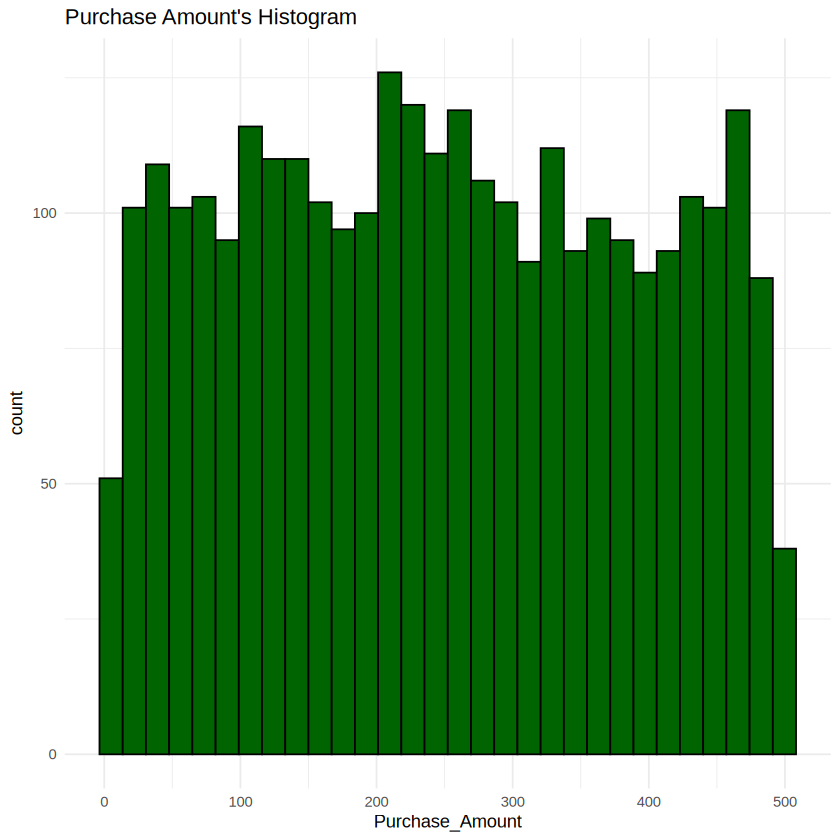

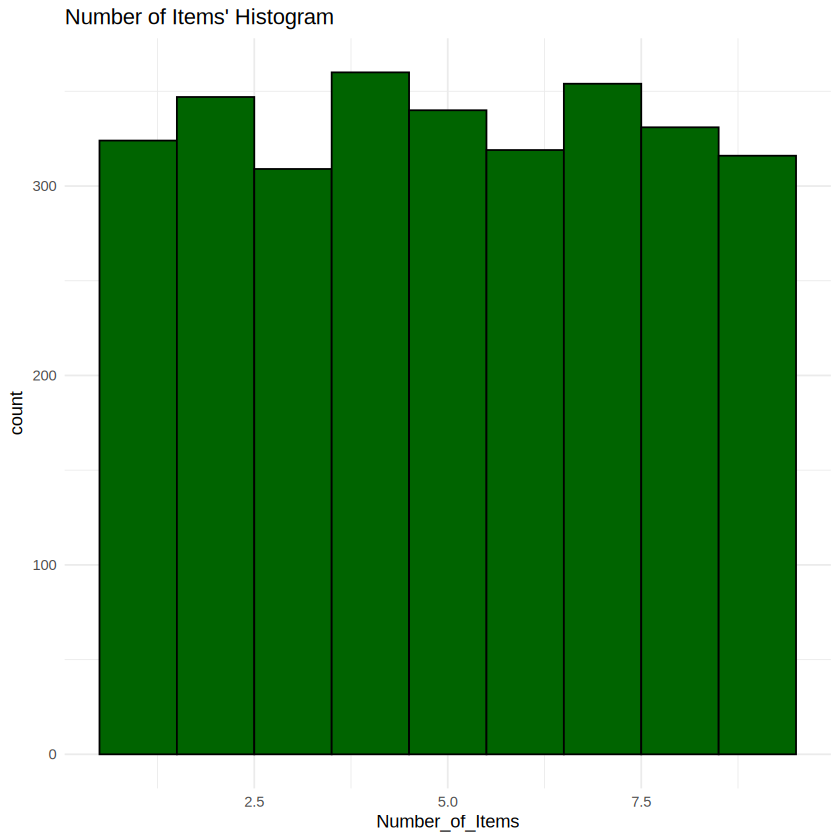

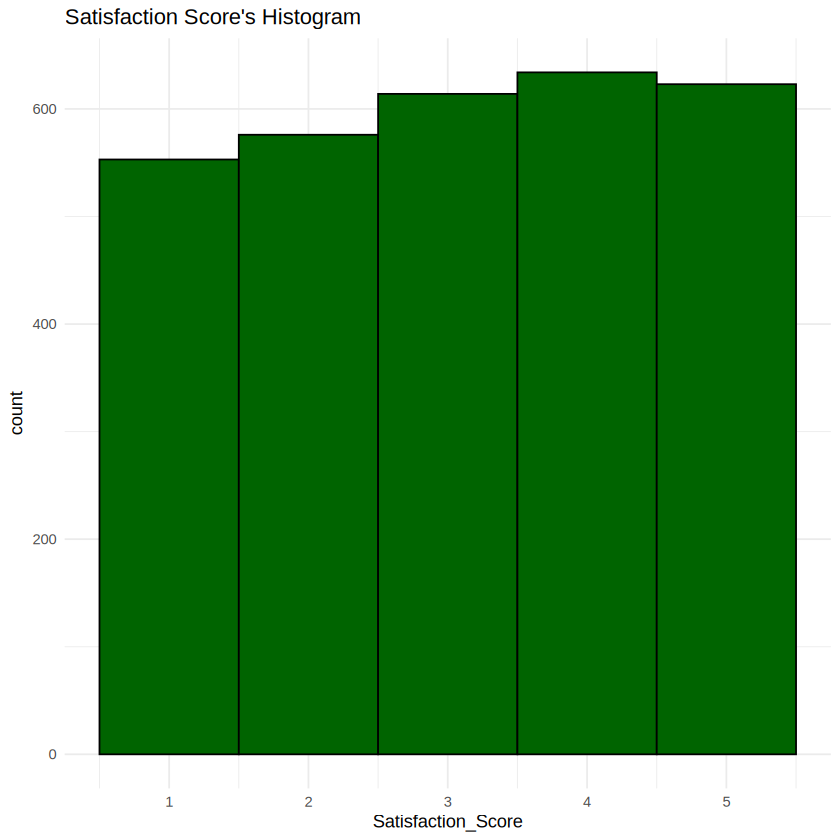

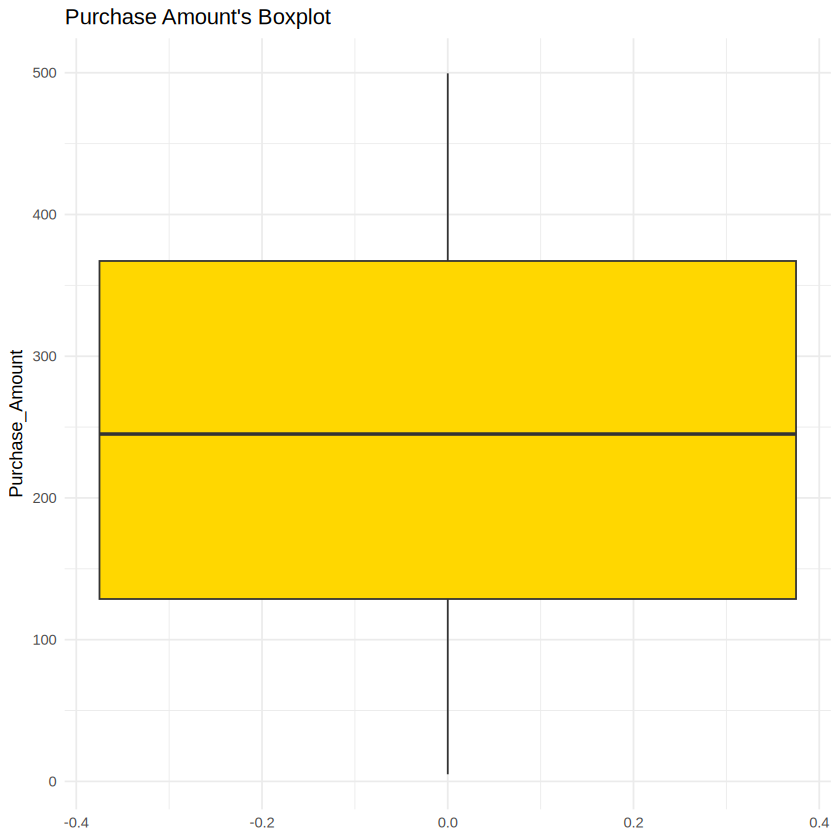

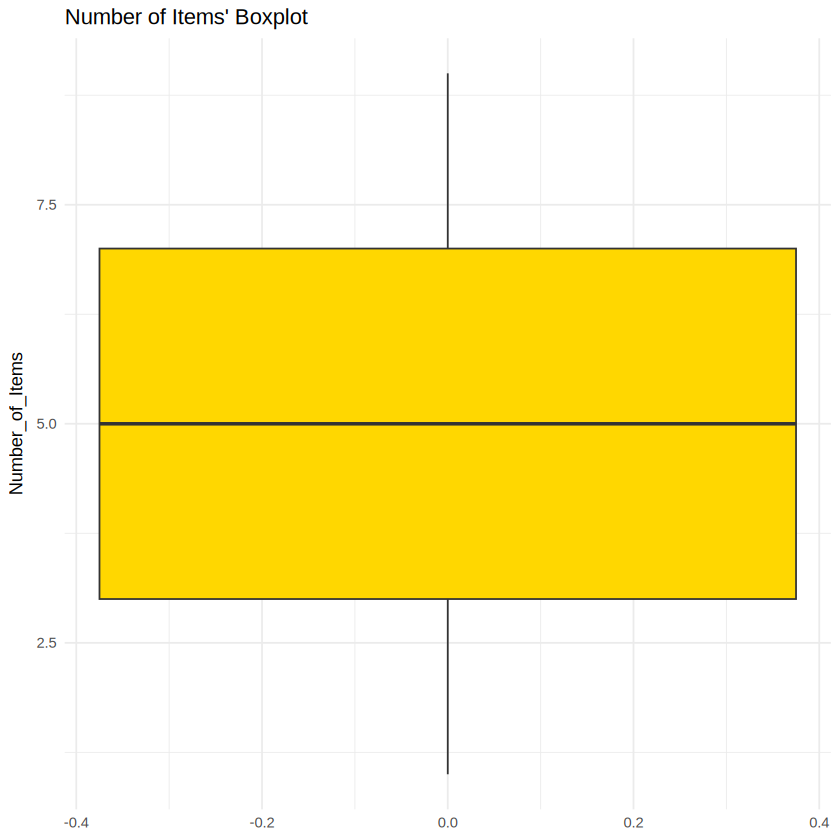

Statistics of Purchase Amount:
Mean: 247.9625 
Median: 245.09 
Mode: 29.33 
Variance: 19845.99 
Standard Deviation: 140.8758 
IQR: 238.505 


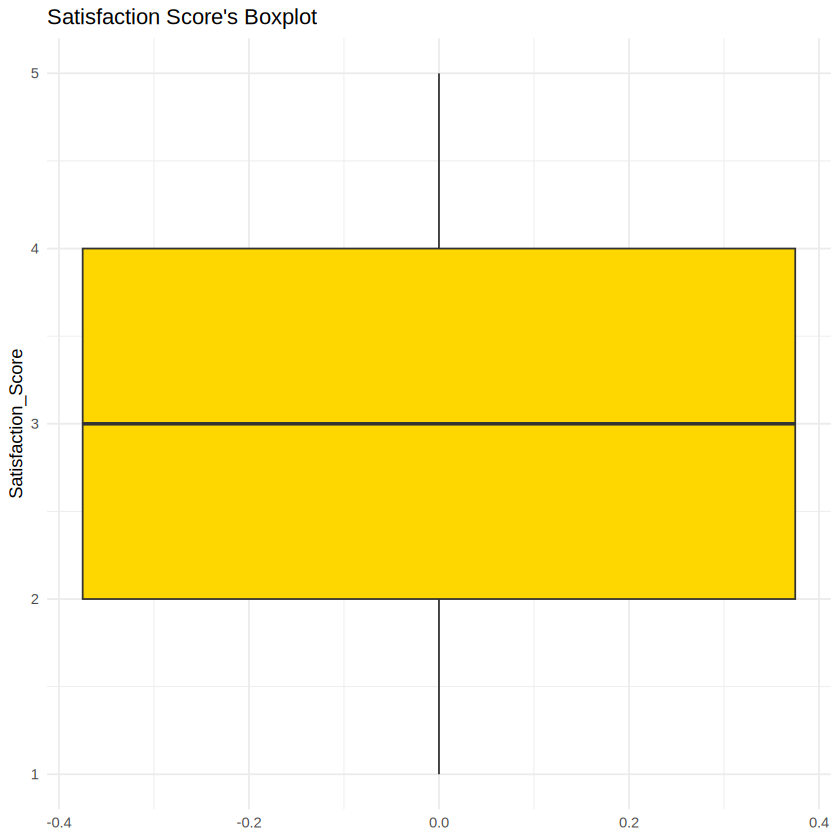

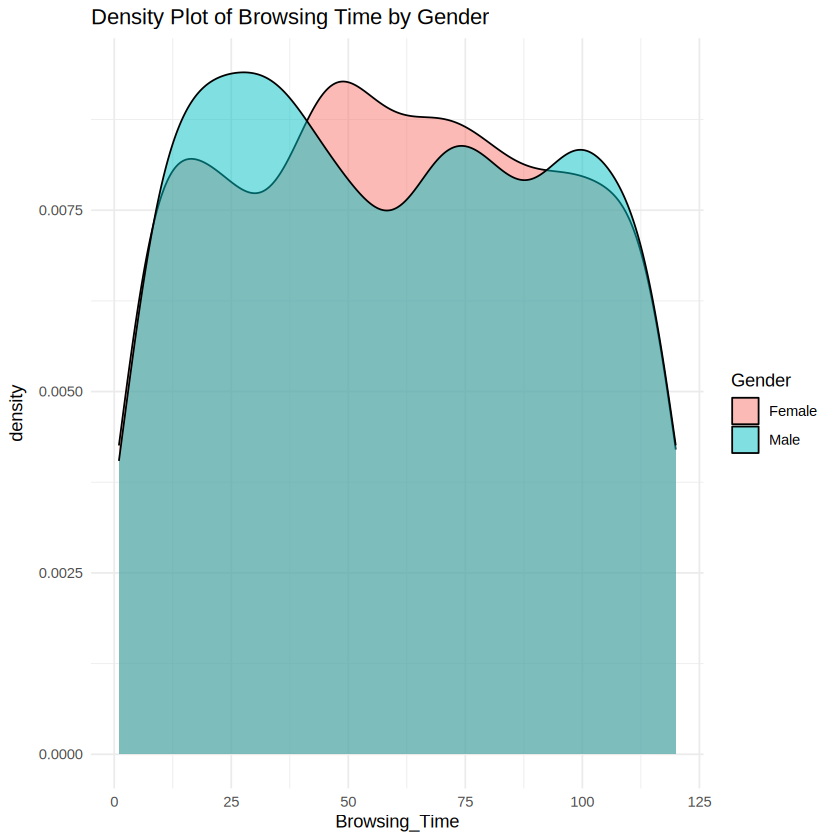


Evaluate Changes in Skewness: 
Original Skewness of Browsing Time: 0.03861558 
Logarithmic Transformation of Browsing Time: -1.218373 



Call:
lm(formula = Purchase_Amount ~ Browsing_Time, data = data_set)

Residuals:
     Min       1Q   Median       3Q      Max 
-244.867 -120.473   -2.946  118.246  254.069 

Coefficients:
               Estimate Std. Error t value Pr(>|t|)    
(Intercept)   252.65596    5.17524  48.820   <2e-16 ***
Browsing_Time  -0.07839    0.07501  -1.045    0.296    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 140.9 on 2998 degrees of freedom
Multiple R-squared:  0.0003642,	Adjusted R-squared:  3.075e-05 
F-statistic: 1.092 on 1 and 2998 DF,  p-value: 0.2961


`geom_smooth()` using formula = 'y ~ x'


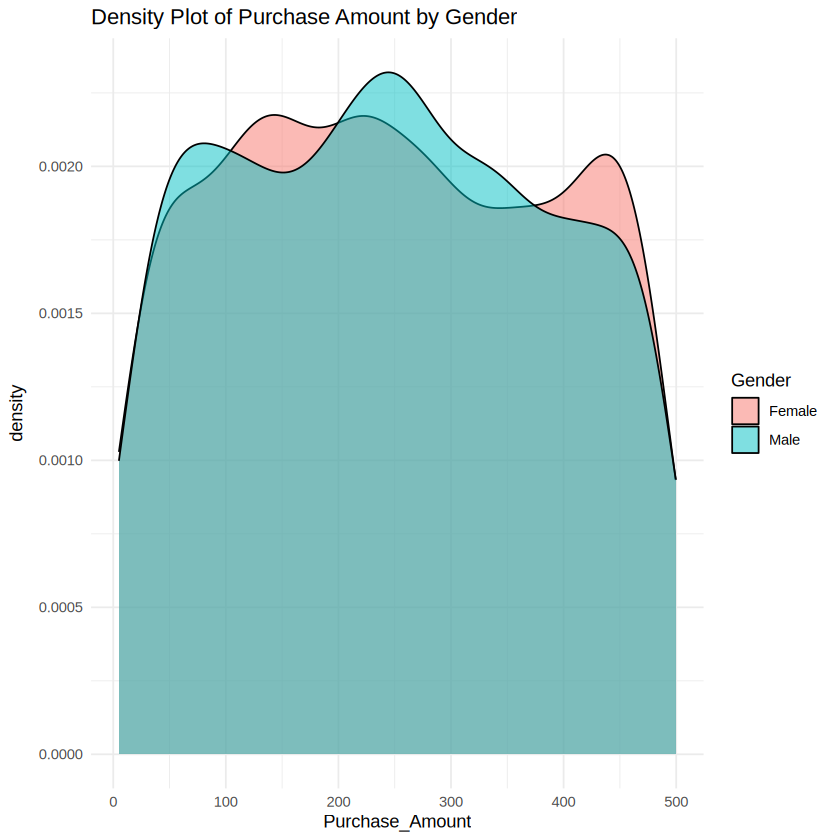

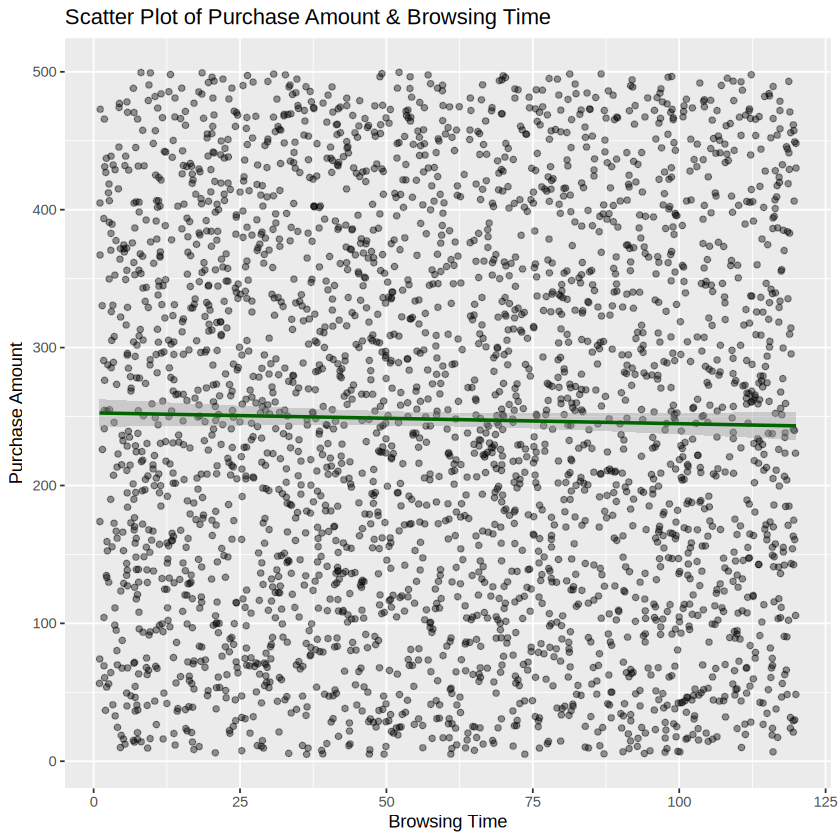

In [12]:
# UNIT 1

if (!requireNamespace("e1071", quietly = TRUE)) {
  install.packages("e1071")
}

library(tidyverse)
library(dplyr)
library(e1071)

# 1 load dataset & summarize
data_set <- read.csv("EDA_Ecommerce_Assessment.csv")
str(data_set)
summary(data_set)

# 2 histograms & boxplots
ggplot(data_set, aes(x = Purchase_Amount)) +
  geom_histogram(fill = "darkgreen", color = "black", bins = 30) +
  ggtitle("Purchase Amount's Histogram") +
  theme_minimal()

ggplot(data_set, aes(x = Number_of_Items)) +
  geom_histogram(fill = "darkgreen", color = "black", binwidth = 1) +
  ggtitle("Number of Items' Histogram") +
  theme_minimal()

ggplot(data_set, aes(x = Satisfaction_Score)) +
  geom_histogram(fill = "darkgreen", color = "black", binwidth = 1) +
  ggtitle("Satisfaction Score's Histogram") +
  theme_minimal()

ggplot(data_set, aes(y = Purchase_Amount)) +
  geom_boxplot(fill = "gold") +
  ggtitle("Purchase Amount's Boxplot") +
  theme_minimal()

ggplot(data_set, aes( y = Number_of_Items)) +
  geom_boxplot(fill = "gold") +
  ggtitle("Number of Items' Boxplot") +
  theme_minimal()

ggplot(data_set, aes(y = Satisfaction_Score)) +
  geom_boxplot(fill = "gold") +
  ggtitle("Satisfaction Score's Boxplot") +
  theme_minimal()

#3 central tendency & spread
mean_purchase <- mean(data_set$Purchase_Amount, na.rm = TRUE)
median_purchase <- median(data_set$Purchase_Amount, na.rm = TRUE)

compute_mode <- function(v) {
  uniqv <- unique(na.omit(v))
  uniqv[which.max(tabulate(match(v, uniqv)))]
}
mode_purchase <- compute_mode(data_set$Purchase_Amount)

var_purchase <- var(data_set$Purchase_Amount, na.rm = TRUE)
sd_purchase <- sd(data_set$Purchase_Amount, na.rm = TRUE)
iqr_purchase <- IQR(data_set$Purchase_Amount, na.rm = TRUE)

cat("Statistics of Purchase Amount:\n")
cat("Mean:", mean_purchase, "\nMedian:", median_purchase,
    "\nMode:", mode_purchase, "\n")
cat("Variance:", var_purchase, "\nStandard Deviation:", sd_purchase,
    "\nIQR:", iqr_purchase, "\n")

# 4 compare
ggplot(data_set, aes(x = Browsing_Time, fill = Gender)) +
  geom_density(alpha = 0.5) +
  ggtitle("Density Plot of Browsing Time by Gender") +
  theme_minimal()

ggplot(data_set, aes(x = Purchase_Amount, fill = Gender)) +
  geom_density(alpha = 0.5) +
  ggtitle("Density Plot of Purchase Amount by Gender") +
  theme_minimal()

# 5 skewness
orig_skew <- skewness(data_set$Browsing_Time, na.rm = TRUE)
data_set$Log_Browsing_Time <- log1p(data_set$Browsing_Time)
log_skew <- skewness(data_set$Log_Browsing_Time, na.rm = TRUE)

cat("\nEvaluate Changes in Skewness: \n")
cat("Original Skewness of Browsing Time:", orig_skew, "\n")
cat("Logarithmic Transformation of Browsing Time:", log_skew, "\n")

#6 linear regression
linear_model <- lm(Purchase_Amount ~ Browsing_Time, data = data_set)
summary(linear_model)

#7
ggplot(data_set, aes(x = Browsing_Time, y = Purchase_Amount)) +
  geom_point(alpha = 0.4, color = "black") +
  geom_smooth(method = "lm", color = "dark green", se = TRUE) +
  labs(title = "Scatter Plot of Purchase Amount & Browsing Time",
        x = "Browsing Time", y = "Purchase Amount")


Call:
lm(formula = Purchase_Amount ~ poly(Browsing_Time, 2, raw = TRUE), 
    data = dataset)

Residuals:
    Min      1Q  Median      3Q     Max 
-245.47 -120.41   -3.49  118.25  255.85 

Coefficients:
                                      Estimate Std. Error t value Pr(>|t|)    
(Intercept)                         249.715045   7.986151  31.269   <2e-16 ***
poly(Browsing_Time, 2, raw = TRUE)1   0.064709   0.305301   0.212    0.832    
poly(Browsing_Time, 2, raw = TRUE)2  -0.001182   0.002445  -0.484    0.629    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 140.9 on 2997 degrees of freedom
Multiple R-squared:  0.0004422,	Adjusted R-squared:  -0.0002249 
F-statistic: 0.6629 on 2 and 2997 DF,  p-value: 0.5154


Model Comparison: 
Polynomial Model: 38206.58 
Simple Linear Model: 38204.81 



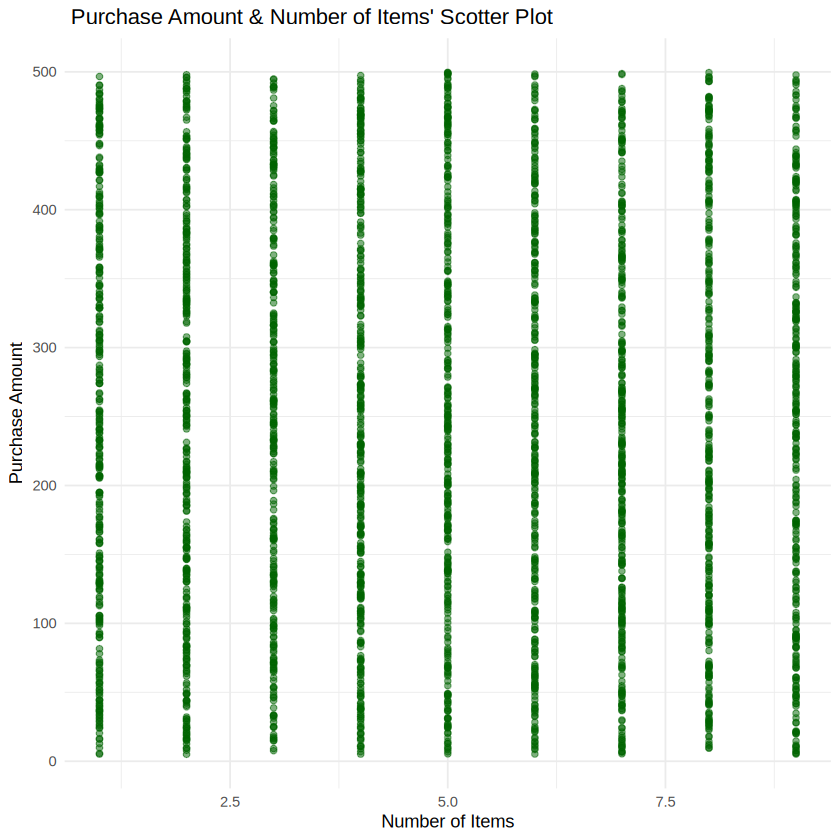

`geom_smooth()` using formula = 'y ~ x'


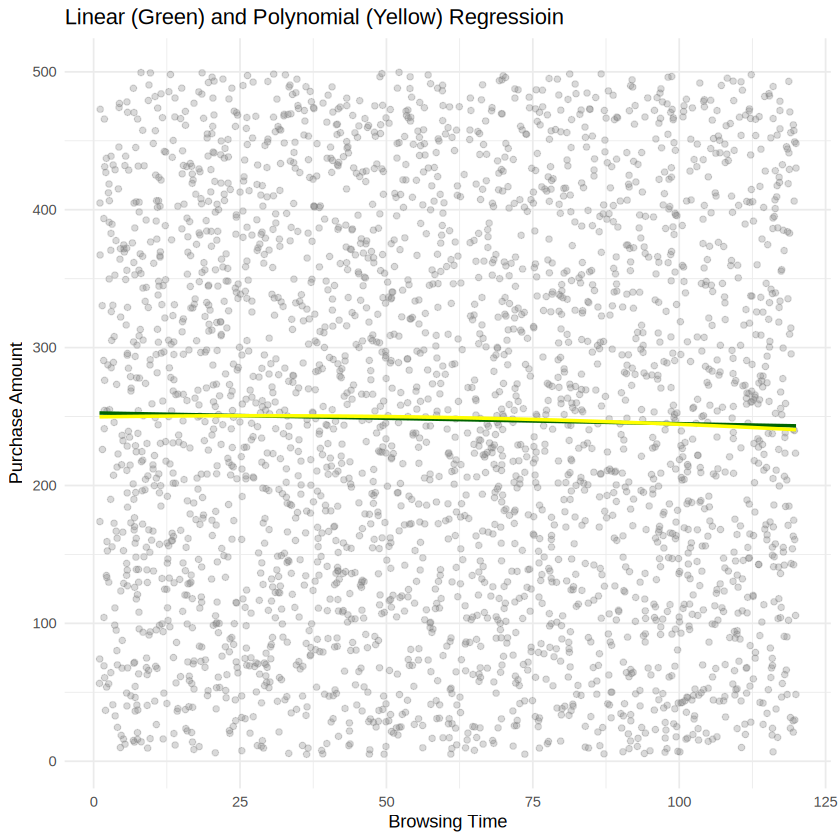

Ordinary LEast Squares (OLS): 
  (Intercept) Browsing_Time 
 252.65595638   -0.07839485 

Robust Regression using Huber:
  (Intercept) Browsing_Time 
 252.64618558   -0.08026744 


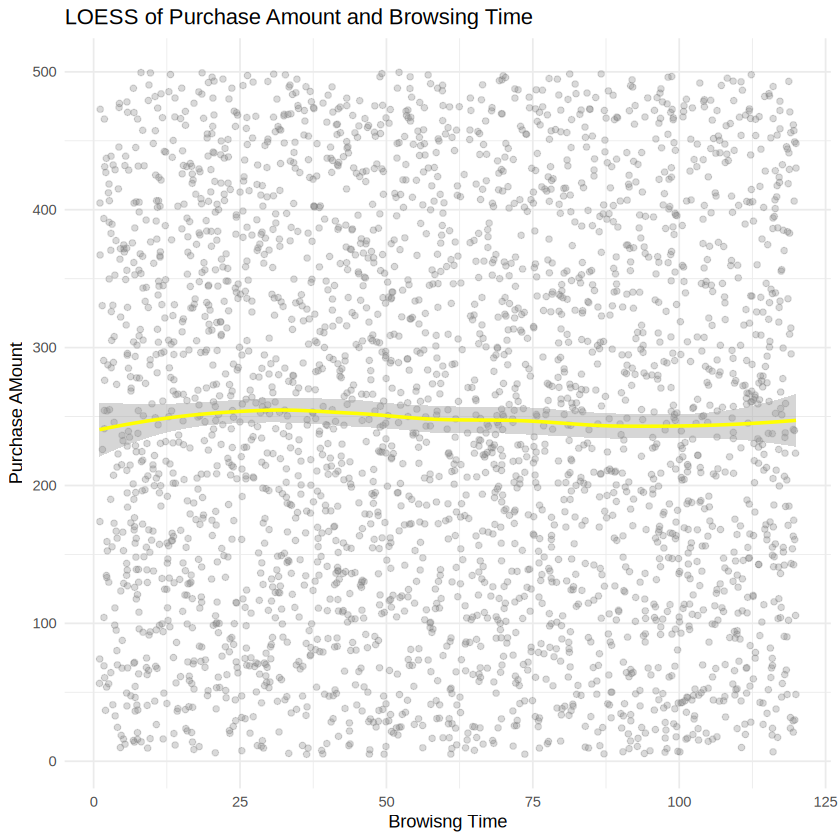

In [21]:
# UNIT 2

library(tidyverse)
library(dplyr)
library(MASS) #robust regression (rlm)

dataset <- read.csv("EDA_Ecommerce_Assessment.csv")

# 8 scatter plot
ggplot(dataset, aes(x = Number_of_Items, y = Purchase_Amount)) +
  geom_point(alpha = 0.5, color = "dark green") +
  labs(title = " Purchase Amount & Number of Items' Scotter Plot",
        x = "Number of Items", y = "Purchase Amount") +
  theme_minimal()

#9 polynomial regression model vs simple linear model
poly_model <- lm(Purchase_Amount ~ poly(Browsing_Time, 2, raw = TRUE), data = dataset)
simple_model <- lm(Purchase_Amount ~ Browsing_Time, data = dataset)
summary(poly_model)

cat("Model Comparison: \n")
cat("Polynomial Model:", AIC(poly_model), "\n")
cat("Simple Linear Model:", AIC(simple_model), "\n\n")

ggplot(dataset, aes(x = Browsing_Time, y = Purchase_Amount)) +
  geom_point(alpha = 0.3, color = "gray50") +
  geom_smooth(method = "lm", formula = y ~ x, color = "dark green", se = FALSE) +
  geom_smooth(method = "lm", formula = y ~ poly(x, 2), color = "yellow", se = FALSE) +
  labs(title = "Linear (Green) and Polynomial (Yellow) Regressioin",
        x = "Browsing Time", y = "Purchase Amount") +
  theme_minimal()

# 10
ggplot(dataset, aes(x = Browsing_Time, y = Purchase_Amount)) +
  geom_point(alpha = 0.3, color = "gray50") +
  geom_smooth(method = "loess", color = "yellow", se = TRUE, span = 0.75) +
  labs(title = "LOESS of Purchase Amount and Browsing Time",
        x = "Browisng Time", y = "Purchase AMount") +
  theme_minimal()

#11
huber_model <- rlm(Purchase_Amount ~ Browsing_Time, data = dataset)

cat("Ordinary LEast Squares (OLS): \n")
print(coef(simple_model))
cat("\nRobust Regression using Huber:\n")
print(coef(huber_model))